In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


In [3]:
df = pd.read_csv(
    "train.csv",
    dtype={"Postal Code": "string"}
)

# Keep a separate copy of the original data
df_raw = df.copy()

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 9800
Columns: 18


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   string 
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

In [6]:
print("Missing values:")
print(df.isna().sum())

print("\nFully duplicated rows:", df.duplicated().sum())

print("\nUnique orders:", df["Order ID"].nunique())
print("Unique customers:", df["Customer ID"].nunique())

Missing values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64

Fully duplicated rows: 0

Unique orders: 4922
Unique customers: 793


In [7]:
# Remove spaces from column names
df.columns = df.columns.str.strip()

# Clean text values while preserving missing values
text_columns = df.select_dtypes(
    include=["object", "string"]
).columns

for column in text_columns:
    df[column] = df[column].str.strip()
    df[column] = df[column].replace("", pd.NA)

In [8]:
for column in ["Order Date", "Ship Date"]:
    df[column] = pd.to_datetime(
        df[column],
        format="%d/%m/%Y",
        errors="raise"
    )

df[["Order Date", "Ship Date"]].head()

,Order Date,Ship Date
0,2017-11-08,2017-11-11
1,2017-11-08,2017-11-11
2,2017-06-12,2017-06-16
3,2016-10-11,2016-10-18
4,2016-10-11,2016-10-18


In [9]:
# Ensure postal codes are stored as text
df["Postal Code"] = df["Postal Code"].astype("string")

# Restore leading zeros for existing US postal codes
df["Postal Code"] = df["Postal Code"].str.zfill(5)

print("Missing postal codes:", df["Postal Code"].isna().sum())

Missing postal codes: 11


In [10]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate Row IDs:", df["Row ID"].duplicated().sum())

df["Sales"] = pd.to_numeric(df["Sales"], errors="raise")

print("Missing sales:", df["Sales"].isna().sum())
print("Zero or negative sales:", (df["Sales"] <= 0).sum())

Fully duplicated rows: 0
Duplicate Row IDs: 0
Missing sales: 0
Zero or negative sales: 0


In [11]:
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Order Month Name"] = df["Order Date"].dt.month_name()

df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print(
    "Shipments before order date:",
    (df["Shipping Days"] < 0).sum()
)

df[[
    "Order Date",
    "Ship Date",
    "Order Year",
    "Order Month",
    "Shipping Days"
]].head()

Shipments before order date: 0


,Order Date,Ship Date,Order Year,Order Month,Shipping Days
0,2017-11-08,2017-11-11,2017,11,3
1,2017-11-08,2017-11-11,2017,11,3
2,2017-06-12,2017-06-16,2017,6,4
3,2016-10-11,2016-10-18,2016,10,7
4,2016-10-11,2016-10-18,2016,10,7


In [12]:
# Confirm cleaning preserved records and sales
assert len(df) == len(df_raw)
assert df["Row ID"].is_unique
assert df["Sales"].notna().all()
assert (df["Shipping Days"] >= 0).all()
assert abs(df["Sales"].sum() - df_raw["Sales"].sum()) < 0.000001

print("Rows:", len(df))
print("Total sales:", round(df["Sales"].sum(), 2))
print("Cleaning checks passed.")

df.to_csv(
    "retail_sales_cleaned.csv",
    index=False,
    date_format="%Y-%m-%d"
)

files.download("retail_sales_cleaned.csv")

Rows: 9800
Total sales: 2261536.78
Cleaning checks passed.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
total_sales = df["Sales"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
average_order_value = total_sales / total_orders

print(f"Total Sales: {total_sales:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Average Order Value: {average_order_value:,.2f}")

Total Sales: 2,261,536.78
Total Orders: 4,922
Total Customers: 793
Average Order Value: 459.48


In [14]:
category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

category_sales["Sales Share (%)"] = (
    category_sales["Sales"] / total_sales * 100
)

display(category_sales.round(2))

,Category,Sales,Sales Share (%)
0,Technology,827455.87,36.59
1,Furniture,728658.58,32.22
2,Office Supplies,705422.33,31.19


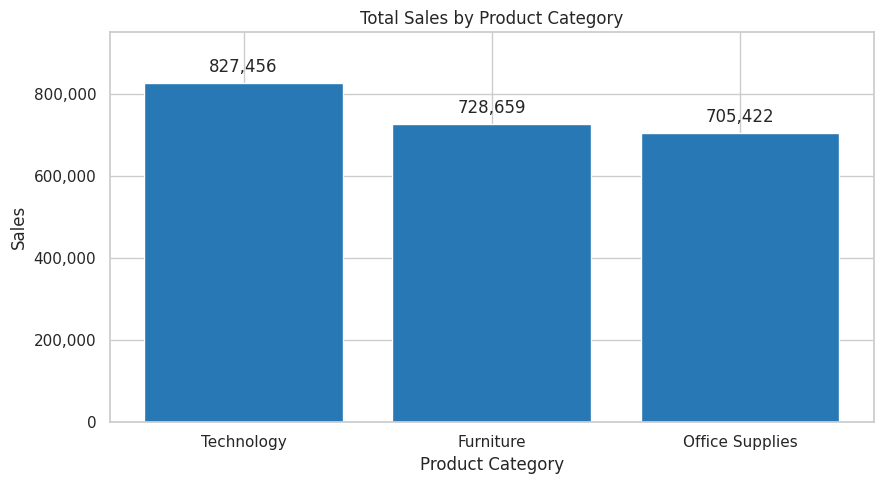

In [15]:
from matplotlib.ticker import StrMethodFormatter

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    category_sales["Category"],
    category_sales["Sales"],
    color="#2878B5"
)

ax.set_title("Total Sales by Product Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("Sales")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():,.0f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

ax.margins(y=0.15)
plt.tight_layout()
plt.show()

In [16]:
annual_sales = (
    df.groupby("Order Year")["Sales"]
    .sum()
    .sort_index()
    .reset_index()
)

# Percentage change compared with the previous year
annual_sales["YoY Growth (%)"] = (
    annual_sales["Sales"].pct_change() * 100
)

display(annual_sales.round(2))

,Order Year,Sales,YoY Growth (%)
0,2015,479856.21,NaN
1,2016,459436.01,-4.26
2,2017,600192.55,30.64
3,2018,722052.02,20.30


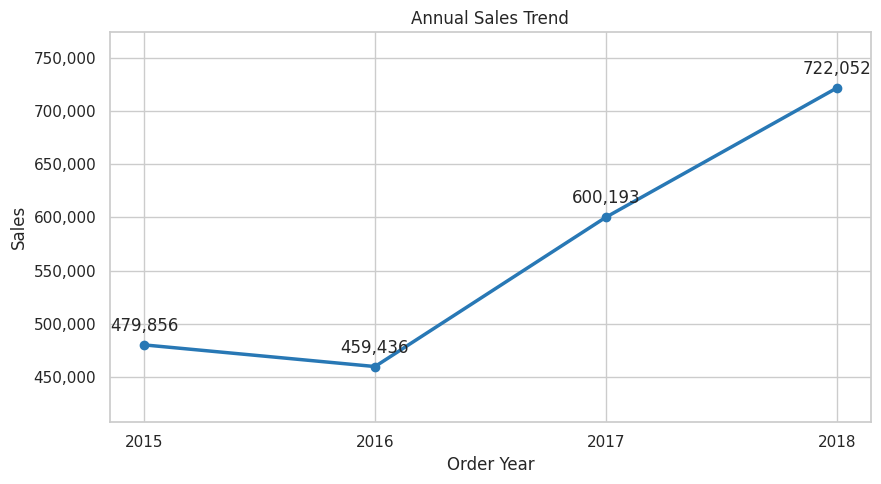

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    annual_sales["Order Year"],
    annual_sales["Sales"],
    marker="o",
    linewidth=2.5,
    color="#2878B5"
)

ax.set_title("Annual Sales Trend")
ax.set_xlabel("Order Year")
ax.set_ylabel("Sales")

# Show whole years and readable sales values
ax.set_xticks(annual_sales["Order Year"])
ax.yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

for year, sales in zip(
    annual_sales["Order Year"],
    annual_sales["Sales"]
):
    ax.annotate(
        f"{sales:,.0f}",
        (year, sales),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center"
    )

ax.margins(y=0.2)
plt.tight_layout()
plt.show()

In [18]:
best_year = annual_sales.loc[
    annual_sales["Sales"].idxmax()
]

best_growth_year = annual_sales.loc[
    annual_sales["YoY Growth (%)"].idxmax()
]

print(
    f"Highest sales: {int(best_year['Order Year'])} "
    f"with {best_year['Sales']:,.2f}"
)

print(
    f"Highest YoY growth: "
    f"{int(best_growth_year['Order Year'])} "
    f"at {best_growth_year['YoY Growth (%)']:.2f}%"
)

Highest sales: 2018 with 722,052.02
Highest YoY growth: 2017 at 30.64%


In [19]:
monthly_sales = (
    df.set_index("Order Date")["Sales"]
    .resample("MS")
    .sum()
)

display(monthly_sales.to_frame("Sales").round(2))

,Sales
Order Date,
2015-01-01,14205.71
2015-02-01,4519.89
2015-03-01,55205.80
2015-04-01,27906.86
2015-05-01,23644.30
2015-06-01,34322.94
2015-07-01,33781.54
2015-08-01,27117.54
2015-09-01,81623.53


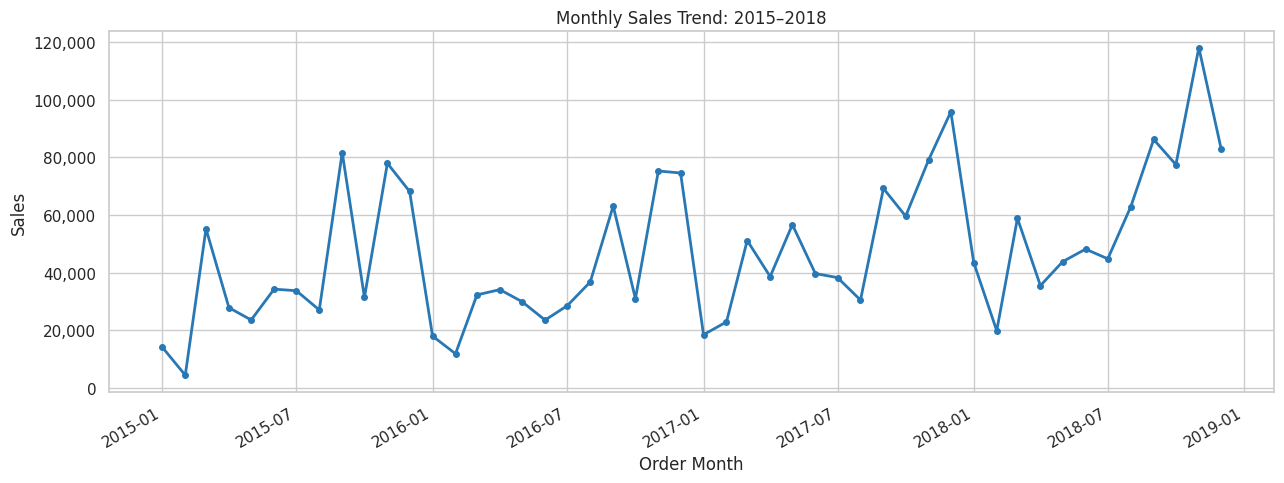

In [20]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    monthly_sales.index,
    monthly_sales.values,
    color="#2878B5",
    linewidth=2,
    marker="o",
    markersize=4
)

ax.set_title("Monthly Sales Trend: 2015–2018")
ax.set_xlabel("Order Month")
ax.set_ylabel("Sales")
ax.yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [21]:
month_year_sales = df.pivot_table(
    index="Order Month",
    columns="Order Year",
    values="Sales",
    aggfunc="sum"
).reindex(range(1, 13))

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

month_year_sales.index = month_names

display(month_year_sales.round(2))

Order Year,2015,2016,2017,2018
Jan,14205.71,18066.96,18542.49,43476.47
Feb,4519.89,11951.41,22978.82,19921.00
Mar,55205.80,32339.32,51165.06,58863.41
Apr,27906.86,34154.47,38679.77,35541.91
May,23644.30,29959.53,56656.91,43825.98
Jun,34322.94,23599.37,39724.49,48190.73
Jul,33781.54,28608.26,38320.78,44825.10
Aug,27117.54,36818.34,30542.20,62837.85
Sep,81623.53,63133.61,69193.39,86152.89
Oct,31453.39,31011.74,59583.03,77448.13


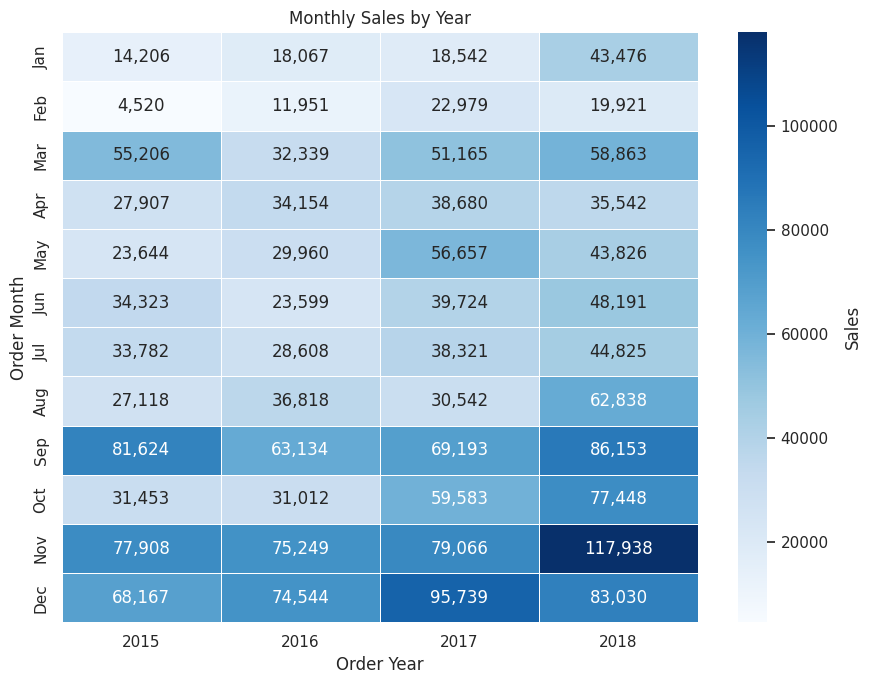

In [22]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    month_year_sales,
    cmap="Blues",
    annot=True,
    fmt=",.0f",
    linewidths=0.5,
    cbar_kws={"label": "Sales"}
)

plt.title("Monthly Sales by Year")
plt.xlabel("Order Year")
plt.ylabel("Order Month")
plt.tight_layout()
plt.show()

In [23]:
print(
    f"Highest-sales month: "
    f"{monthly_sales.idxmax():%B %Y} "
    f"— {monthly_sales.max():,.2f}"
)

print(
    f"Lowest-sales month: "
    f"{monthly_sales.idxmin():%B %Y} "
    f"— {monthly_sales.min():,.2f}"
)

Highest-sales month: November 2018 — 117,938.15
Lowest-sales month: February 2015 — 4,519.89


In [24]:
region_summary = (
    df.groupby("Region")
    .agg(
        Sales=("Sales", "sum"),
        Orders=("Order ID", "nunique"),
        Customers=("Customer ID", "nunique")
    )
    .sort_values("Sales", ascending=False)
)

region_summary["Sales Share (%)"] = (
    region_summary["Sales"] / df["Sales"].sum() * 100
)

region_summary["Average Order Value"] = (
    region_summary["Sales"] / region_summary["Orders"]
)

display(region_summary.round(2))

,Sales,Orders,Customers,Sales Share (%),Average Order Value
Region,,,,,
West,710219.68,1587,681,31.40,447.52
East,669518.73,1369,669,29.60,489.06
Central,492646.91,1156,626,21.78,426.17
South,389151.46,810,509,17.21,480.43


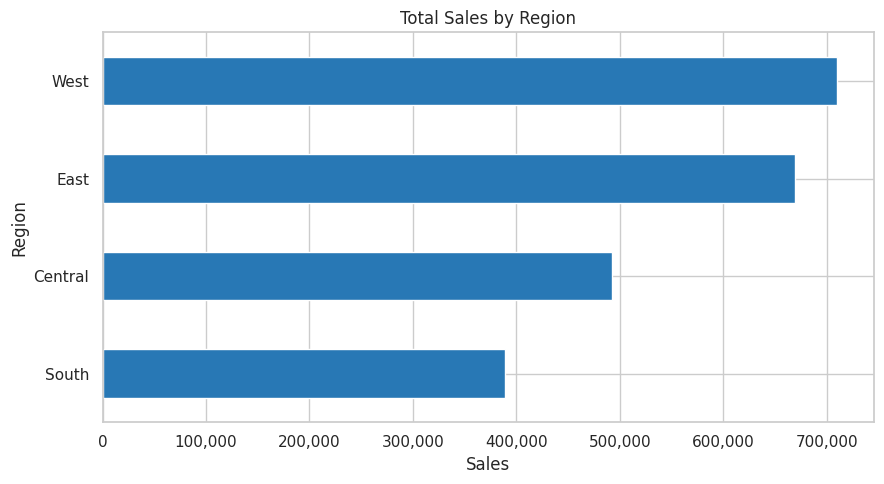

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))

region_summary["Sales"].sort_values().plot(
    kind="barh",
    ax=ax,
    color="#2878B5"
)

ax.set_title("Total Sales by Region")
ax.set_xlabel("Sales")
ax.set_ylabel("Region")
ax.xaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

plt.tight_layout()
plt.show()

In [26]:
segment_summary = (
    df.groupby("Segment")
    .agg(
        Sales=("Sales", "sum"),
        Orders=("Order ID", "nunique"),
        Customers=("Customer ID", "nunique")
    )
    .sort_values("Sales", ascending=False)
)

segment_summary["Sales Share (%)"] = (
    segment_summary["Sales"] / df["Sales"].sum() * 100
)

segment_summary["Average Order Value"] = (
    segment_summary["Sales"] / segment_summary["Orders"]
)

display(segment_summary.round(2))

,Sales,Orders,Customers,Sales Share (%),Average Order Value
Segment,,,,,
Consumer,1148060.53,2537,409,50.76,452.53
Corporate,688494.07,1491,236,30.44,461.77
Home Office,424982.18,894,148,18.79,475.37


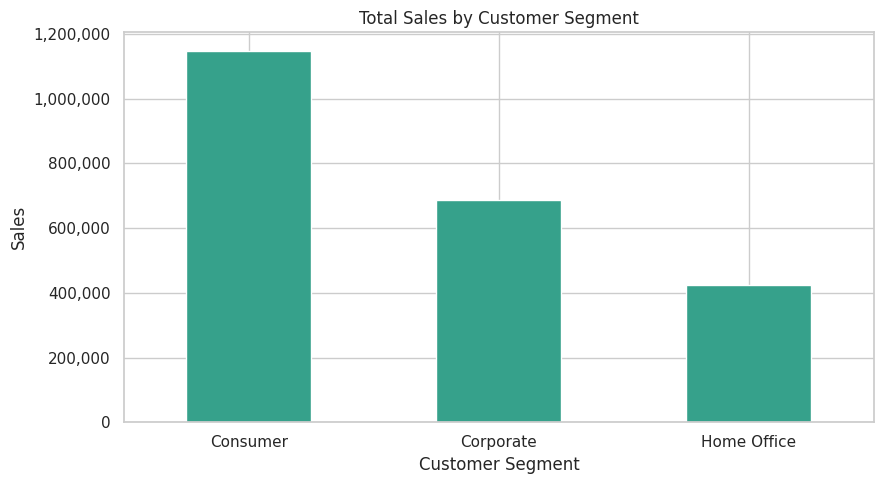

In [27]:
fig, ax = plt.subplots(figsize=(9, 5))

segment_summary["Sales"].plot(
    kind="bar",
    ax=ax,
    color="#36A18B"
)

ax.set_title("Total Sales by Customer Segment")
ax.set_xlabel("Customer Segment")
ax.set_ylabel("Sales")
ax.tick_params(axis="x", rotation=0)
ax.yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

plt.tight_layout()
plt.show()

In [28]:
subcategory_sales = (
    df.groupby("Sub-Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

display(subcategory_sales.to_frame("Sales").round(2))

,Sales
Sub-Category,
Phones,327782.45
Chairs,322822.73
Storage,219343.39
Tables,202810.63
Binders,200028.78
Machines,189238.63
Accessories,164186.70
Copiers,146248.09
Bookcases,113813.20


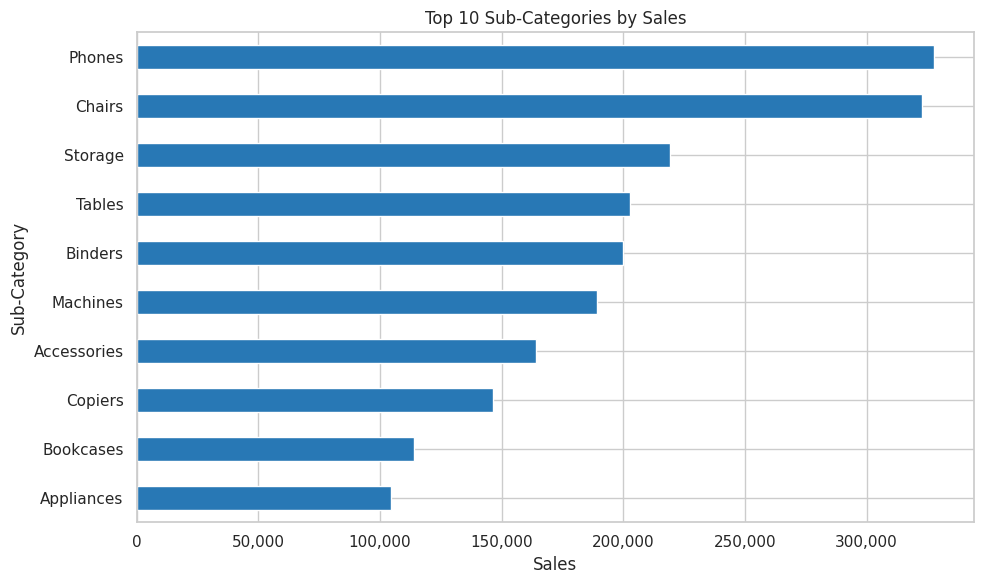

In [29]:
fig, ax = plt.subplots(figsize=(10, 6))

subcategory_sales.head(10).sort_values().plot(
    kind="barh",
    ax=ax,
    color="#2878B5"
)

ax.set_title("Top 10 Sub-Categories by Sales")
ax.set_xlabel("Sales")
ax.set_ylabel("Sub-Category")
ax.xaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

plt.tight_layout()
plt.show()

In [30]:
customer_summary = (
    df.groupby(["Customer ID", "Customer Name"])
    .agg(
        Sales=("Sales", "sum"),
        Orders=("Order ID", "nunique")
    )
    .sort_values("Sales", ascending=False)
    .reset_index()
)

customer_summary["Average Order Value"] = (
    customer_summary["Sales"] / customer_summary["Orders"]
)

display(customer_summary.head(10).round(2))

,Customer ID,Customer Name,Sales,Orders,Average Order Value
0,SM-20320,Sean Miller,25043.05,5,5008.61
1,TC-20980,Tamara Chand,19052.22,5,3810.44
2,RB-19360,Raymond Buch,15117.34,6,2519.56
3,TA-21385,Tom Ashbrook,14595.62,4,3648.90
4,AB-10105,Adrian Barton,14473.57,10,1447.36
5,KL-16645,Ken Lonsdale,14175.23,12,1181.27
6,SC-20095,Sanjit Chand,14142.33,9,1571.37
7,HL-15040,Hunter Lopez,12873.30,6,2145.55
8,SE-20110,Sanjit Engle,12209.44,11,1109.95
9,CC-12370,Christopher Conant,12129.07,5,2425.81


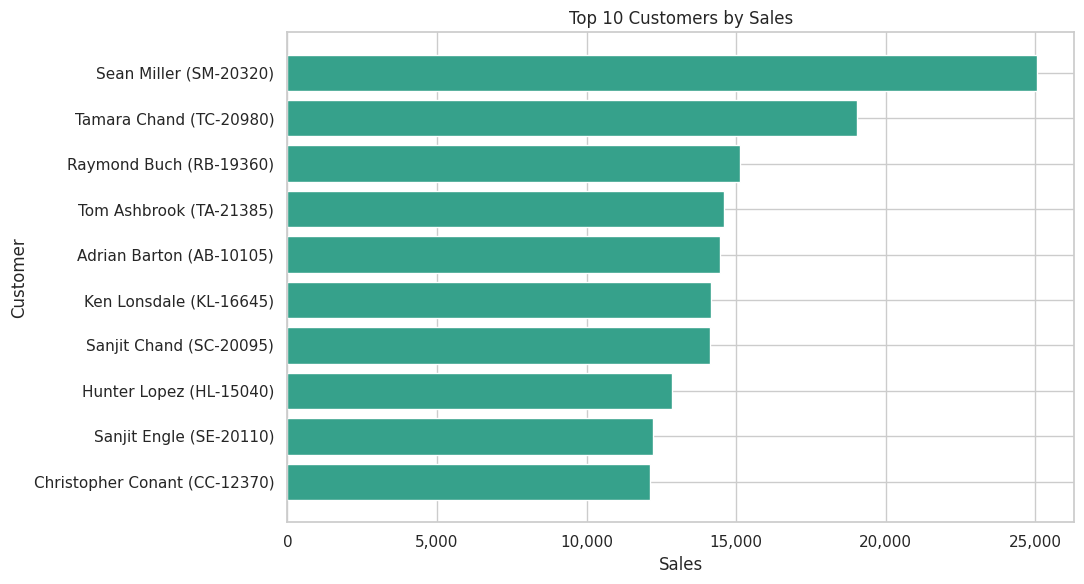

In [31]:
top_customers = customer_summary.head(10).copy()

top_customers["Customer Label"] = (
    top_customers["Customer Name"]
    + " (" + top_customers["Customer ID"] + ")"
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    top_customers["Customer Label"],
    top_customers["Sales"],
    color="#36A18B"
)

ax.invert_yaxis()
ax.set_title("Top 10 Customers by Sales")
ax.set_xlabel("Sales")
ax.set_ylabel("Customer")
ax.xaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

plt.tight_layout()
plt.show()

In [32]:
top_10_share = (
    customer_summary.head(10)["Sales"].sum()
    / df["Sales"].sum()
    * 100
)

print(
    f"Top 10 customers contributed "
    f"{top_10_share:.2f}% of total sales."
)

Top 10 customers contributed 6.80% of total sales.


In [33]:
shipping_check = (
    df.groupby("Order ID")[
        ["Order Date", "Ship Date", "Ship Mode"]
    ]
    .nunique(dropna=False)
)

inconsistent_orders = shipping_check.gt(1).any(axis=1)

print(
    "Orders with conflicting shipping details:",
    inconsistent_orders.sum()
)

Orders with conflicting shipping details: 0


In [34]:
orders = df[[
    "Order ID",
    "Order Date",
    "Ship Date",
    "Ship Mode",
    "Shipping Days"
]].drop_duplicates(subset="Order ID")

print("Unique orders:", len(orders))
print(
    "Average days to shipment:",
    round(orders["Shipping Days"].mean(), 2)
)
print(
    "Median days to shipment:",
    orders["Shipping Days"].median()
)

Unique orders: 4922
Average days to shipment: 3.96
Median days to shipment: 4.0


In [35]:
shipping_summary = (
    orders.groupby("Ship Mode")
    .agg(
        Orders=("Order ID", "count"),
        Average_Days=("Shipping Days", "mean"),
        Median_Days=("Shipping Days", "median"),
        Minimum_Days=("Shipping Days", "min"),
        Maximum_Days=("Shipping Days", "max")
    )
    .sort_values("Average_Days")
)

display(shipping_summary.round(2))

,Orders,Average_Days,Median_Days,Minimum_Days,Maximum_Days
Ship Mode,,,,,
Same Day,261,0.05,0.0,0,1
First Class,772,2.19,2.0,1,4
Second Class,944,3.24,3.0,1,5
Standard Class,2945,5.00,5.0,3,7


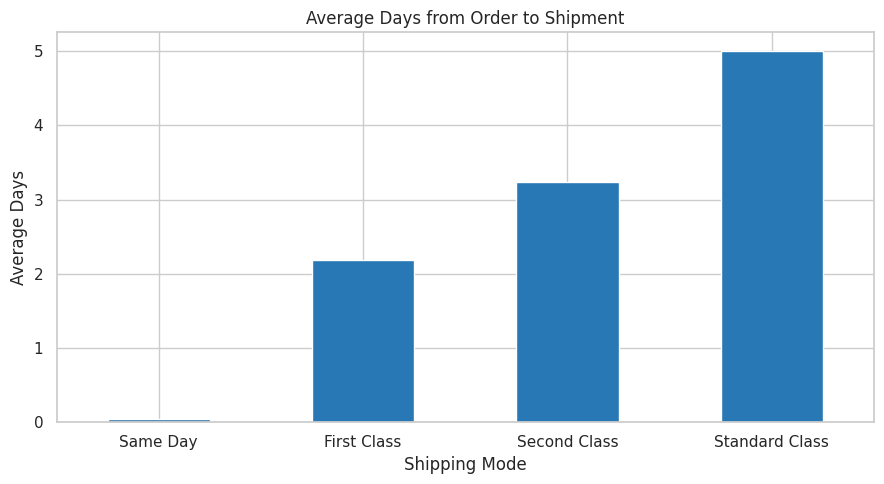

In [36]:
fig, ax = plt.subplots(figsize=(9, 5))

shipping_summary["Average_Days"].plot(
    kind="bar",
    ax=ax,
    color="#2878B5"
)

ax.set_title("Average Days from Order to Shipment")
ax.set_xlabel("Shipping Mode")
ax.set_ylabel("Average Days")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [37]:
import sqlite3

conn = sqlite3.connect("retail_sales.db")

# Create a SQL-friendly copy with simpler column names
sql_df = df.copy()

sql_df.columns = (
    sql_df.columns
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Store dates as ISO text for SQLite
for column in ["order_date", "ship_date"]:
    sql_df[column] = sql_df[column].dt.strftime("%Y-%m-%d")

sql_df.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

print("Data loaded into the sales table.")

Data loaded into the sales table.


In [38]:
query = """
SELECT *
FROM sales
LIMIT 5;
"""

display(pd.read_sql_query(query, conn))

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,region,product_id,category,sub_category,product_name,sales,order_year,order_month,order_month_name,shipping_days
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2017,11,November,3
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,2017,11,November,3
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2017,6,June,4
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,2016,10,October,7
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2016,10,October,7


In [39]:
query = """
SELECT
    COUNT(*) AS sales_line_items,
    COUNT(DISTINCT order_id) AS total_orders,
    COUNT(DISTINCT customer_id) AS total_customers,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(
        SUM(sales) / NULLIF(COUNT(DISTINCT order_id), 0),
        2
    ) AS average_order_value
FROM sales;
"""

sql_kpis = pd.read_sql_query(query, conn)
display(sql_kpis)

,sales_line_items,total_orders,total_customers,total_sales,average_order_value
0,9800,4922,793,2261536.78,459.48


In [40]:
query = """
SELECT
    category,
    ROUND(SUM(sales), 2) AS total_sales,
    COUNT(DISTINCT order_id) AS orders,
    ROUND(
        100.0 * SUM(sales) /
        (SELECT SUM(sales) FROM sales),
        2
    ) AS sales_share_pct
FROM sales
GROUP BY category
ORDER BY total_sales DESC;
"""

sql_category_sales = pd.read_sql_query(query, conn)
display(sql_category_sales)

,category,total_sales,orders,sales_share_pct
0,Technology,827455.87,1519,36.59
1,Furniture,728658.58,1727,32.22
2,Office Supplies,705422.33,3676,31.19


In [41]:
assert sql_kpis.loc[0, "sales_line_items"] == len(df)

assert (
    sql_kpis.loc[0, "total_orders"]
    == df["Order ID"].nunique()
)

assert abs(
    sql_kpis.loc[0, "total_sales"] - df["Sales"].sum()
) < 0.01

print("SQL totals match Python.")

SQL totals match Python.


In [42]:
query = """
WITH annual_sales AS (
    SELECT
        order_year,
        SUM(sales) AS total_sales
    FROM sales
    GROUP BY order_year
),
previous_sales AS (
    SELECT
        order_year,
        total_sales,
        LAG(total_sales) OVER (
            ORDER BY order_year
        ) AS previous_year_sales
    FROM annual_sales
)
SELECT
    order_year,
    ROUND(total_sales, 2) AS total_sales,
    ROUND(
        100.0 * (total_sales - previous_year_sales)
        / NULLIF(previous_year_sales, 0),
        2
    ) AS yoy_growth_pct
FROM previous_sales
ORDER BY order_year;
"""

sql_annual_sales = pd.read_sql_query(query, conn)
display(sql_annual_sales)

,order_year,total_sales,yoy_growth_pct
0,2015,479856.21,NaN
1,2016,459436.01,-4.26
2,2017,600192.55,30.64
3,2018,722052.02,20.30


In [43]:
query = """
SELECT
    region,
    ROUND(SUM(sales), 2) AS total_sales,
    COUNT(DISTINCT order_id) AS total_orders,
    ROUND(
        SUM(sales)
        / NULLIF(COUNT(DISTINCT order_id), 0),
        2
    ) AS average_order_value,
    ROUND(
        100.0 * SUM(sales)
        / (SELECT SUM(sales) FROM sales),
        2
    ) AS sales_share_pct
FROM sales
GROUP BY region
ORDER BY total_sales DESC;
"""

sql_region_sales = pd.read_sql_query(query, conn)
display(sql_region_sales)

,region,total_sales,total_orders,average_order_value,sales_share_pct
0,West,710219.68,1587,447.52,31.40
1,East,669518.73,1369,489.06,29.60
2,Central,492646.91,1156,426.17,21.78
3,South,389151.46,810,480.43,17.21


In [44]:
query = """
SELECT
    customer_id,
    customer_name,
    ROUND(SUM(sales), 2) AS total_sales,
    COUNT(DISTINCT order_id) AS total_orders,
    ROUND(
        SUM(sales)
        / NULLIF(COUNT(DISTINCT order_id), 0),
        2
    ) AS average_order_value
FROM sales
GROUP BY customer_id, customer_name
ORDER BY SUM(sales) DESC, customer_id
LIMIT 10;
"""

sql_top_customers = pd.read_sql_query(query, conn)
display(sql_top_customers)

,customer_id,customer_name,total_sales,total_orders,average_order_value
0,SM-20320,Sean Miller,25043.05,5,5008.61
1,TC-20980,Tamara Chand,19052.22,5,3810.44
2,RB-19360,Raymond Buch,15117.34,6,2519.56
3,TA-21385,Tom Ashbrook,14595.62,4,3648.91
4,AB-10105,Adrian Barton,14473.57,10,1447.36
5,KL-16645,Ken Lonsdale,14175.23,12,1181.27
6,SC-20095,Sanjit Chand,14142.33,9,1571.37
7,HL-15040,Hunter Lopez,12873.30,6,2145.55
8,SE-20110,Sanjit Engle,12209.44,11,1109.95
9,CC-12370,Christopher Conant,12129.07,5,2425.81


In [45]:
query = """
SELECT
    category,
    sub_category,
    ROUND(SUM(sales), 2) AS total_sales
FROM sales
GROUP BY category, sub_category
ORDER BY SUM(sales) DESC, category, sub_category
LIMIT 5;
"""

sql_top_subcategories = pd.read_sql_query(query, conn)
display(sql_top_subcategories)

,category,sub_category,total_sales
0,Technology,Phones,327782.45
1,Furniture,Chairs,322822.73
2,Office Supplies,Storage,219343.39
3,Furniture,Tables,202810.63
4,Office Supplies,Binders,200028.79


In [46]:
python_annual = (
    df.groupby("Order Year")["Sales"]
    .sum()
    .sort_index()
)

sql_annual = (
    sql_annual_sales
    .set_index("order_year")["total_sales"]
    .sort_index()
)

assert python_annual.index.equals(sql_annual.index)
assert (python_annual - sql_annual).abs().lt(0.01).all()

print("Annual SQL sales match Python.")

Annual SQL sales match Python.
